In [1]:
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

AP=SASAfinal/SASAinitial; SASA:solvent-accessible surface area
|   AP Value | Initial Interpretation               |
| ------: | ------------------ |
|    Close to 1 | The surface area changes little before and after simulation, indicating weak aggregation tendency |
|    Greater than 1 | Some degree of aggregation occurs          |
| Greater than approximately 1.5 | Usually considered to indicate a clear aggregation tendency     |


In [2]:
import pandas as pd

data_path = Path("Sequential_Peptides/collection_of_peptide_data.csv")

if not data_path.exists():
    raise FileNotFoundError(
        "Data file was not found. Please check the CSV path and modify data_path."
    )

df = pd.read_csv(data_path)

print("Data shape (df.shape):")
print(df.shape)

print("\nColumn names:")
print(list(df.columns))

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
display(df.dtypes)

print("\nMissing values in each column:")
display(df.isna().sum())

Data shape (df.shape):
(62159, 2)

Column names:
['Feature', 'Label']

First 5 rows:


,Feature,Label
0,EADPN,0.999
1,DADPA,1.001
2,DNPEI,1.001
3,DDPMD,1.004
4,EQDLP,1.005



Data types:


Feature        str
Label      float64
dtype: object


Missing values in each column:


Feature    0
Label      0
dtype: int64

In [3]:
print("Total number of samples:", len(df))
print("Number of fully duplicated rows:", df.duplicated().sum())

print("\nNumber of unique values in each column:")
display(df.nunique())

print("\nSummary statistics for numeric columns:")
display(df.describe())

Total number of samples: 62159
Number of fully duplicated rows: 0

Number of unique values in each column:


Feature    62144
Label       1414
dtype: int64


Summary statistics for numeric columns:


,Label
count,62159.000000
mean,1.739095
std,0.211039
min,0.993000
25%,1.626000
50%,1.752000
75%,1.871000
max,2.619000


In [4]:
data = df[["Feature", "Label"]].copy()

data["Feature"] = data["Feature"].astype(str).str.strip().str.upper()
data["Label"] = pd.to_numeric(data["Label"], errors="coerce")

print("Number of samples before cleaning:", len(data))

data = data.dropna()
data = data.drop_duplicates()

print("Number of samples after cleaning:", len(data))

Number of samples before cleaning: 62159
Number of samples after cleaning: 62159


In [5]:
data["length"] = data["Feature"].str.len()

length_counts = data["length"].value_counts().sort_index()

print("Number of samples for each sequence length:")
display(length_counts.to_frame(name="sample_count"))

Number of samples for each sequence length:


,sample_count
length,
5,10450
6,9713
7,9644
8,9892
9,9656
10,12804


In [6]:
standard_amino_acids = set("ACDEFGHIKLMNPQRSTVWY")

observed_amino_acids = set("".join(data["Feature"].tolist()))

invalid_amino_acids = observed_amino_acids - standard_amino_acids
missing_amino_acids = standard_amino_acids - observed_amino_acids

print("Amino acids observed in the dataset:")
print(sorted(observed_amino_acids))

print("\nInvalid characters:")
print(sorted(invalid_amino_acids))

print("\nStandard amino acids not observed in the dataset:")
print(sorted(missing_amino_acids))

Amino acids observed in the dataset:
['A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'V', 'W', 'Y']

Invalid characters:
[]

Standard amino acids not observed in the dataset:
[]


In [7]:
def contains_only_standard_amino_acids(sequence: str) -> bool:
    return set(sequence).issubset(standard_amino_acids)

data["is_valid_sequence"] = data["Feature"].apply(
    contains_only_standard_amino_acids
)

print("Number of valid sequences:", data["is_valid_sequence"].sum())
print("Number of invalid sequences:", (~data["is_valid_sequence"]).sum())

Number of valid sequences: 62159
Number of invalid sequences: 0


In [8]:
print("Descriptive statistics of the AP label:")
display(data["Label"].describe())

Descriptive statistics of the AP label:


count    62159.000000
mean         1.739095
std          0.211039
min          0.993000
25%          1.626000
50%          1.752000
75%          1.871000
max          2.619000
Name: Label, dtype: float64

In [9]:
aggregation_threshold = 1.5

aggregating_count = (data["Label"] > aggregation_threshold).sum()
aggregating_ratio = (data["Label"] > aggregation_threshold).mean()

print("Number of samples with AP > 1.5:", aggregating_count)
print(f"Proportion of samples with AP > 1.5:{aggregating_ratio:.2%}")

Number of samples with AP > 1.5: 55189
Proportion of samples with AP > 1.5:88.79%


In [10]:
summary_by_length = (
    data.groupby("length")["Label"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

print("AP statistics by sequence length:")
display(summary_by_length)

AP statistics by sequence length:


,count,mean,median,std,min,max
length,,,,,,
5,10450,1.785172,1.827,0.292533,0.999,2.619
6,9713,1.759360,1.792,0.237662,0.994,2.462
7,9644,1.727718,1.748,0.202532,0.993,2.386
8,9892,1.696596,1.712,0.175366,1.015,2.275
9,9656,1.682737,1.692,0.152564,1.009,2.184
10,12804,1.770020,1.776,0.156343,1.016,2.315


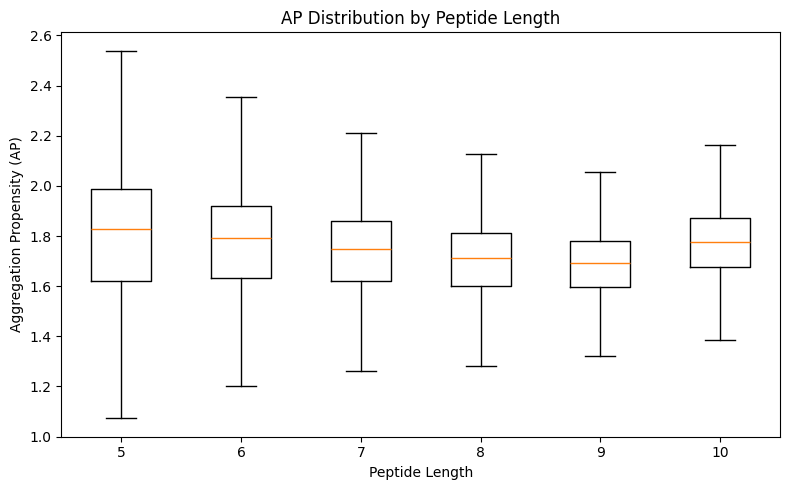

In [11]:
lengths = sorted(data["length"].unique())

ap_groups = [
    data.loc[data["length"] == length, "Label"]
    for length in lengths
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    ap_groups,
    tick_labels=lengths,
    showfliers=False
)

plt.xlabel("Peptide Length")
plt.ylabel("Aggregation Propensity (AP)")
plt.title("AP Distribution by Peptide Length")

plt.tight_layout()
plt.show()

In [12]:
results_dir = Path("results")
figures_dir = Path("figures")

results_dir.mkdir(exist_ok=True)
figures_dir.mkdir(exist_ok=True)

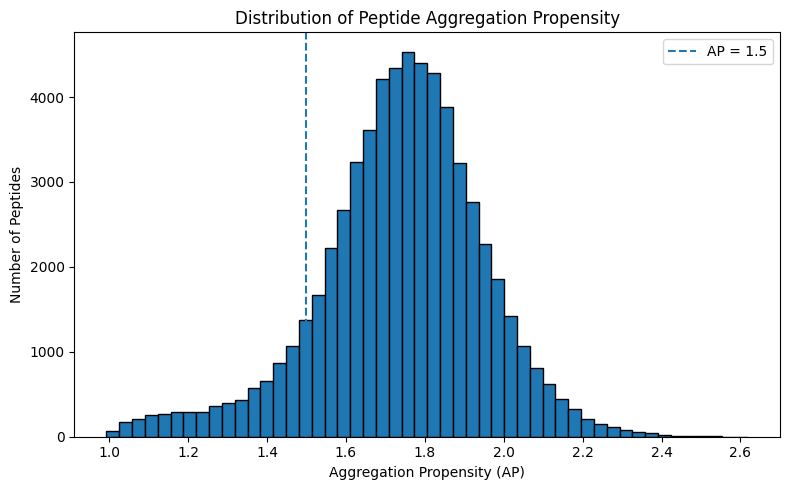

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(
    data["Label"],
    bins=50,
    edgecolor="black"
)

plt.axvline(
    x=1.5,
    linestyle="--",
    label="AP = 1.5"
)

plt.xlabel("Aggregation Propensity (AP)")
plt.ylabel("Number of Peptides")
plt.title("Distribution of Peptide Aggregation Propensity")
plt.legend()

plt.tight_layout()
plt.savefig(
    figures_dir / "ap_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [14]:
print("===== Dataset Summary =====")
print("Number of samples:", len(data))
print("Column names:", list(df.columns))
print("Sequence length range:", data["length"].min(), "-", data["length"].max())
print("Number of invalid sequences:", (~data["is_valid_sequence"]).sum())
print("Number of duplicated samples:", df.duplicated().sum())
print("Minimum AP:", data["Label"].min())
print("Maximum AP:", data["Label"].max())
print("Mean AP:", data["Label"].mean())
print("Median AP:", data["Label"].median())
print(f"Proportion of AP > 1.5:{(data['Label'] > 1.5).mean():.2%}")

print("\n===== Sample Count by Sequence Length =====")
display(length_counts.to_frame(name="sample_count"))

print("\n===== AP Statistics by Sequence Length =====")
display(summary_by_length)

===== Dataset Summary =====
Number of samples: 62159
Column names: ['Feature', 'Label']
Sequence length range: 5 - 10
Number of invalid sequences: 0
Number of duplicated samples: 0
Minimum AP: 0.993
Maximum AP: 2.619
Mean AP: 1.7390948696085844
Median AP: 1.752
Proportion of AP > 1.5:88.79%

===== Sample Count by Sequence Length =====


,sample_count
length,
5,10450
6,9713
7,9644
8,9892
9,9656
10,12804



===== AP Statistics by Sequence Length =====


,count,mean,median,std,min,max
length,,,,,,
5,10450,1.785172,1.827,0.292533,0.999,2.619
6,9713,1.759360,1.792,0.237662,0.994,2.462
7,9644,1.727718,1.748,0.202532,0.993,2.386
8,9892,1.696596,1.712,0.175366,1.015,2.275
9,9656,1.682737,1.692,0.152564,1.009,2.184
10,12804,1.770020,1.776,0.156343,1.016,2.315


In [15]:
AMINO_ACIDS = list("ACDEFGHIKLMNPQRSTVWY")

all_sequences = "".join(data["Feature"].tolist())
overall_counts = Counter(all_sequences)

overall_frequency = pd.DataFrame({
    "amino_acid": AMINO_ACIDS,
    "count": [overall_counts.get(aa, 0) for aa in AMINO_ACIDS]
})

overall_frequency["frequency"] = (
    overall_frequency["count"] / overall_frequency["count"].sum()
)

display(overall_frequency)

,amino_acid,count,frequency
0,A,19838,0.042019
1,C,24025,0.050888
2,D,24298,0.051466
3,E,23803,0.050418
4,F,24122,0.051093
5,G,23953,0.050735
6,H,24104,0.051055
7,I,24296,0.051462
8,K,24023,0.050884
9,L,24105,0.051057


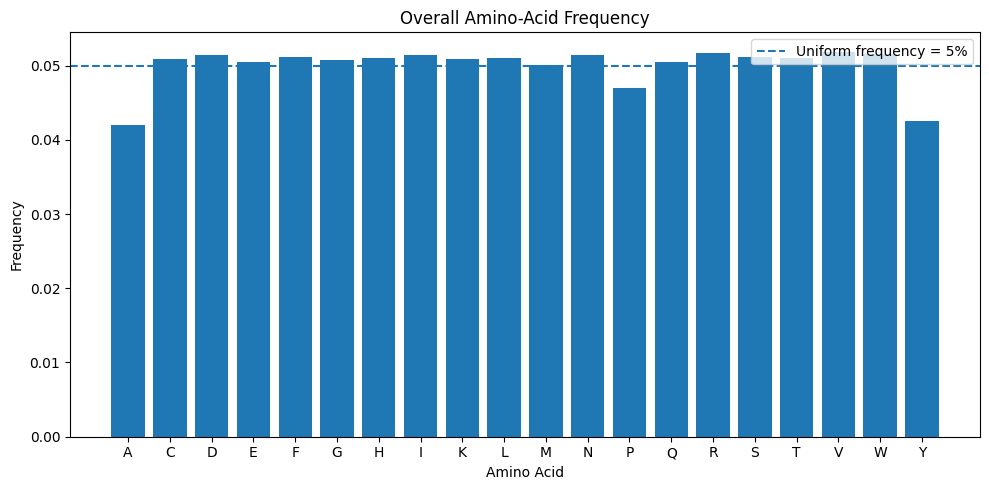

In [16]:
plt.figure(figsize=(10, 5))

plt.bar(
    overall_frequency["amino_acid"],
    overall_frequency["frequency"]
)

plt.axhline(
    y=1 / 20,
    linestyle="--",
    label="Uniform frequency = 5%"
)

plt.xlabel("Amino Acid")
plt.ylabel("Frequency")
plt.title("Overall Amino-Acid Frequency")
plt.legend()

plt.tight_layout()
plt.show()

In [17]:
low_threshold = data["Label"].quantile(0.20)
high_threshold = data["Label"].quantile(0.80)

low_ap_data = data[data["Label"] <= low_threshold].copy()
high_ap_data = data[data["Label"] >= high_threshold].copy()

print("Low-AP threshold:", low_threshold)
print("High-AP threshold:", high_threshold)

print("Low-AP sample count:", len(low_ap_data))
print("High-AP sample count:", len(high_ap_data))

Low-AP threshold: 1.591
High-AP threshold: 1.902
Low-AP sample count: 12493
High-AP sample count: 12501


In [18]:
def calculate_amino_acid_frequency(sequence_series):
    joined_sequences = "".join(sequence_series.tolist())
    counts = Counter(joined_sequences)
    total = sum(counts.values())

    return {
        aa: counts.get(aa, 0) / total
        for aa in AMINO_ACIDS
    }

In [19]:
low_frequency = calculate_amino_acid_frequency(
    low_ap_data["Feature"]
)

high_frequency = calculate_amino_acid_frequency(
    high_ap_data["Feature"]
)

comparison = pd.DataFrame({
    "amino_acid": AMINO_ACIDS,
    "low_AP_frequency": [
        low_frequency[aa] for aa in AMINO_ACIDS
    ],
    "high_AP_frequency": [
        high_frequency[aa] for aa in AMINO_ACIDS
    ]
})

comparison["difference"] = (
    comparison["high_AP_frequency"]
    - comparison["low_AP_frequency"]
)

comparison = comparison.sort_values(
    "difference",
    ascending=False
)

display(comparison)

,amino_acid,low_AP_frequency,high_AP_frequency,difference
18,W,0.009676,0.106654,0.096978
4,F,0.015631,0.097125,0.081494
19,Y,0.012605,0.079601,0.066996
6,H,0.019873,0.063658,0.043785
7,I,0.042024,0.059927,0.017904
9,L,0.042230,0.058591,0.016361
17,V,0.043770,0.058161,0.014391
1,C,0.045430,0.054965,0.009536
12,P,0.043900,0.052374,0.008474
10,M,0.048673,0.055372,0.006699


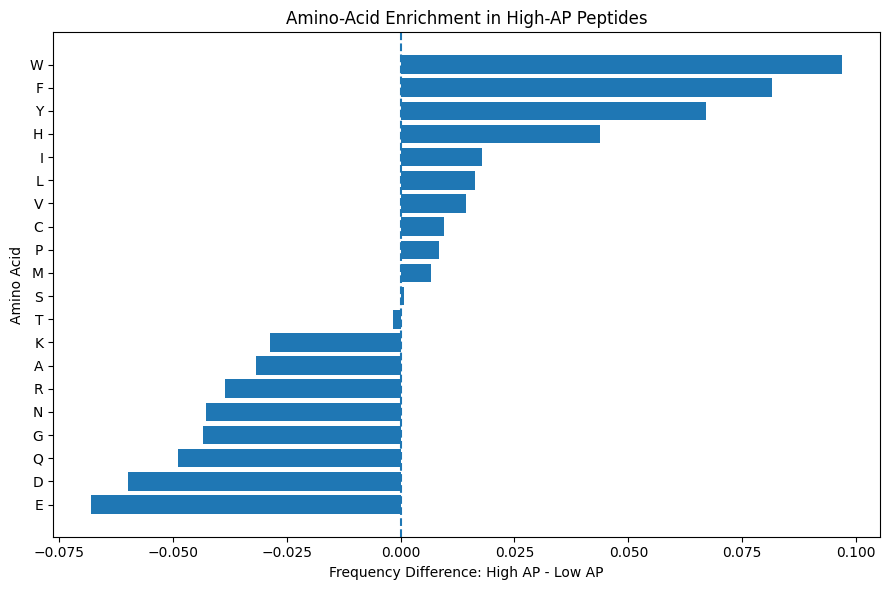

In [20]:
plot_data = comparison.sort_values("difference")

plt.figure(figsize=(9, 6))

plt.barh(
    plot_data["amino_acid"],
    plot_data["difference"]
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.xlabel("Frequency Difference: High AP - Low AP")
plt.ylabel("Amino Acid")
plt.title("Amino-Acid Enrichment in High-AP Peptides")

plt.tight_layout()
plt.show()

In [21]:
penta_data = data[data["length"] == 5].copy()

print("Number of pentapeptides:", len(penta_data))


Number of pentapeptides: 10450


In [22]:
def calculate_position_frequency(
    dataframe,
    sequence_column="Feature"
):
    sequence_length = dataframe[sequence_column].str.len().iloc[0]

    records = []

    for position in range(sequence_length):
        amino_acids_at_position = (
            dataframe[sequence_column]
            .str[position]
        )

        counts = amino_acids_at_position.value_counts()
        total = len(amino_acids_at_position)

        for aa in AMINO_ACIDS:
            records.append({
                "position": position + 1,
                "amino_acid": aa,
                "frequency": counts.get(aa, 0) / total
            })

    return pd.DataFrame(records)

In [23]:
penta_low_threshold = penta_data["Label"].quantile(0.20)
penta_high_threshold = penta_data["Label"].quantile(0.80)

penta_low = penta_data[
    penta_data["Label"] <= penta_low_threshold
].copy()

penta_high = penta_data[
    penta_data["Label"] >= penta_high_threshold
].copy()

print("Low-AP pentapeptides:", len(penta_low))
print("High-AP pentapeptides:", len(penta_high))

Low-AP pentapeptides: 2098
High-AP pentapeptides: 2108


In [24]:
low_position_frequency = calculate_position_frequency(penta_low)
high_position_frequency = calculate_position_frequency(penta_high)

position_comparison = high_position_frequency.merge(
    low_position_frequency,
    on=["position", "amino_acid"],
    suffixes=("_high_AP", "_low_AP")
)

position_comparison["difference"] = (
    position_comparison["frequency_high_AP"]
    - position_comparison["frequency_low_AP"]
)

display(position_comparison.head(20))

,position,amino_acid,frequency_high_AP,frequency_low_AP,difference
0,1,A,0.026091,0.071497,-0.045406
1,1,C,0.055977,0.046711,0.009266
2,1,D,0.012808,0.111058,-0.098250
3,1,E,0.012808,0.099142,-0.086334
4,1,F,0.094877,0.015253,0.079624
5,1,G,0.031309,0.061010,-0.029701
6,1,H,0.041271,0.011916,0.029355
7,1,I,0.067837,0.044805,0.023032
8,1,K,0.038425,0.051478,-0.013053
9,1,L,0.065465,0.043851,0.021614


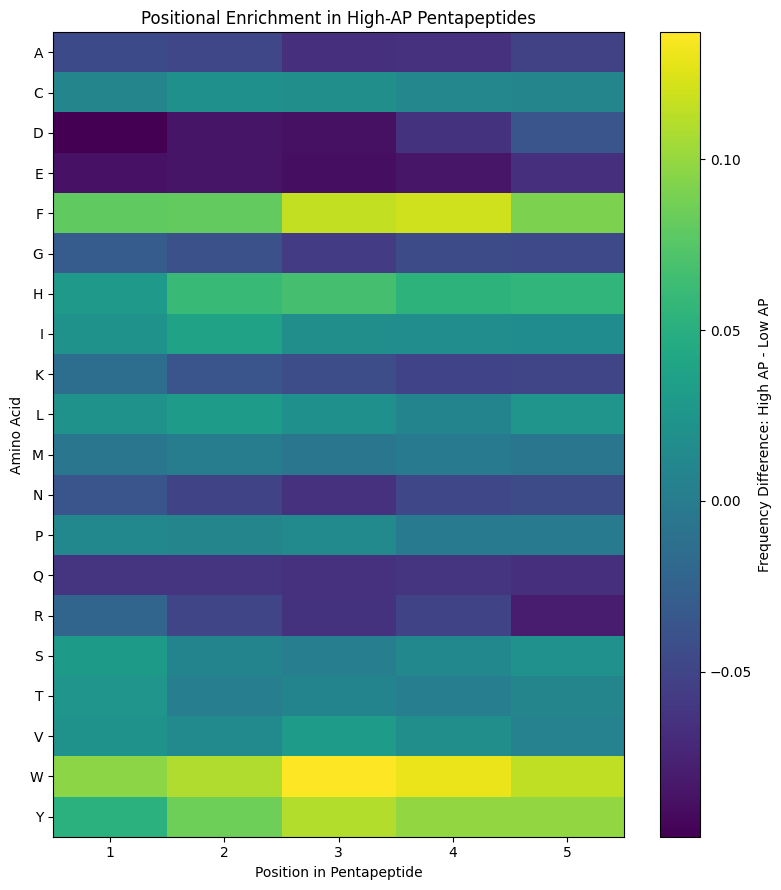

In [25]:
heatmap_data = (
    position_comparison
    .pivot(
        index="amino_acid",
        columns="position",
        values="difference"
    )
    .reindex(AMINO_ACIDS)
)

plt.figure(figsize=(8, 9))

plt.imshow(
    heatmap_data,
    aspect="auto"
)

plt.colorbar(
    label="Frequency Difference: High AP - Low AP"
)

plt.xticks(
    ticks=range(len(heatmap_data.columns)),
    labels=heatmap_data.columns
)

plt.yticks(
    ticks=range(len(heatmap_data.index)),
    labels=heatmap_data.index
)

plt.xlabel("Position in Pentapeptide")
plt.ylabel("Amino Acid")
plt.title("Positional Enrichment in High-AP Pentapeptides")

plt.tight_layout()

plt.savefig(
    figures_dir / "pentapeptide_positional_enrichment.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [26]:
overall_frequency.to_csv(
    results_dir / "overall_amino_acid_frequency.csv",
    index=False
)

comparison.to_csv(
    results_dir / "high_vs_low_ap_amino_acid_frequency.csv",
    index=False
)

position_comparison.to_csv(
    results_dir / "pentapeptide_positional_enrichment.csv",
    index=False
)

Whether the overall amino-acid frequency is close to a uniform distribution, indicating whether the sampling has obvious bias.
Whether high-AP and low-AP peptides show clear differences in amino-acid composition.
Whether aromatic and hydrophobic amino acids tend to be enriched in high-AP peptides.
Whether some charged amino acids show position-dependent effects.
Simple amino-acid composition features can explain part of the variation in AP, but may not fully capture sequence order and local interactions.